# EDA 02 · Members table

**Part I · Raw tables** · part of the 10-notebook EDA series in `workshops/w1/eda/` (index in `README.md`).

**Question.** What do the demographic fields (city, age, gender, registration channel) look like, and which need cleaning?

**Data.** Raw files converted to parquet in `workshops/data/parquet/`. The target is the labelled March cohort `train_v2` (970,960 users, 9.0 % churn).

**How to read it.** Each variable gets a count plot plus a percentile table; age (`bd`) and `registered_via` carry invalid values.

In [ ]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Paths resolve from the w1 folder, whether the notebook runs from workshops/w1 or workshops/w1/eda.
W1_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA_DIR = W1_DIR.parent / "data"      # workshops/data: raw .csv.7z archives
PARQUET_DIR = DATA_DIR / "parquet"     # created once by notebook 01 (or by w1_data_preprocessing)

sns.set()
warnings.filterwarnings("ignore")

PCTS = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 98, 99, 99.5, 99.99, 99.999, 100]


def tabla_percentiles(serie):
    return pd.DataFrame(np.percentile(serie, PCTS), index=PCTS, columns=["valor"])

## 2. Members

In [17]:
# members_v3.parquet; member.csv and member_v2.csv were replaced by the competition sponsors
member_data = pl.read_parquet(PARQUET_DIR / "members_v3.parquet").to_pandas()
member_data["registration_init_time"] = pd.to_datetime(
    member_data["registration_init_time"].astype(str), format="%Y%m%d")

In [18]:
member_data.head()

,msno,city,registered_via,bd,registration_init_time,gender
0,Rb9UwLQTrxzBVwCB6+bCcSQWZ9JiNLC9dXtM1oEsZA8=,1,11,0,2011-09-11,NaN
1,+tJonkh+O1CA796Fm5X60UMOtB6POHAwPjbTRVl/EuU=,1,7,0,2011-09-14,NaN
2,cV358ssn7a0f7jZOwGNWS07wCKVqxyiImJUX6xcIwKw=,1,11,0,2011-09-15,NaN
3,9bzDeJP6sQodK73K5CBlJ6fgIQzPeLnRl0p5B77XP+g=,1,11,0,2011-09-15,NaN
4,WFLY3s7z4EZsieHCt63XrsdtfTEmJ+2PnnKLH5GY4Tk=,6,9,32,2011-09-15,female


This dataframe contains 6 columns. Gender has NaN values, `registration_init_time` is a datetime feature, and gender is given as a string, so label encoding should be used.

In [19]:
member_data.shape  # more users than in our training set

(6769473, 6)

In [20]:
member_data.describe().apply(lambda s: s.apply(lambda x: format(x, "f")))

,city,registered_via,bd,registration_init_time
count,6769473.000000,6769473.000000,6769473.000000,6769473.000000
mean,3.847358,5.253069,9.795794,f
min,1.000000,-1.000000,-7168.000000,f
25%,1.000000,4.000000,0.000000,f
50%,1.000000,4.000000,0.000000,f
75%,4.000000,7.000000,21.000000,f
max,22.000000,19.000000,2016.000000,f
std,5.478359,2.361398,17.925900,nan


The city feature has no outliers (minimum 1, maximum 22). `bd` (age) has outliers because there are negative and very high values. `registered_via` also contains a negative value.

In [21]:
member_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6769473 entries, 0 to 6769472
Data columns (total 6 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   msno                    str           
 1   city                    int8          
 2   registered_via          int8          
 3   bd                      int16         
 4   registration_init_time  datetime64[us]
 5   gender                  str           
dtypes: datetime64[us](1), int16(1), int8(2), str(2)
memory usage: 497.7 MB


Memory of this dataframe can also be optimized.

#### bd stands for age

In [22]:
print(member_data["city"].value_counts())
print("Total number of distinct cities:", member_data["city"].nunique())

city
1     4804326
5      385069
13     320978
4      246848
22     210407
15     190213
6      135200
14      89940
12      66843
9       47639
11      47489
8       45975
18      38039
10      32482
21      30837
17      27772
3       27282
7       11610
16       5092
20       4233
19       1199
Name: count, dtype: int64
Total number of distinct cities: 21


In [23]:
tabla_percentiles(member_data["city"])

,valor
0.000,1.0
10.000,1.0
20.000,1.0
30.000,1.0
40.000,1.0
50.000,1.0
60.000,1.0
70.000,1.0
80.000,5.0
90.000,13.0


City data has no outliers, with city 1 being the highest.

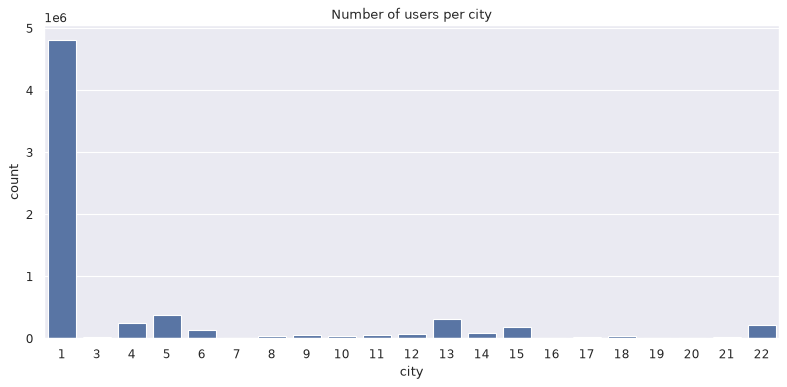

In [24]:
figure(num=None, figsize=(10, 5), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=member_data["city"])
plt.title("Number of users per city")
plt.xlabel("city")
plt.ylabel("count")
plt.tight_layout()
plt.show()

City 1 is dominant over all other cities. Other cities with more users are 4, 5, 13, 15 and 22.

In [25]:
print(member_data["bd"].describe())
print("maximum value:", member_data["bd"].max())
print("minimum value:", member_data["bd"].min())  # clearly contains outliers

count    6.769473e+06
mean     9.795794e+00
std      1.792590e+01
min     -7.168000e+03
25%      0.000000e+00
50%      0.000000e+00
75%      2.100000e+01
max      2.016000e+03
Name: bd, dtype: float64
maximum value: 2016
minimum value: -7168


In [26]:
# percentiles because the maximum values of these features are unusually high
tabla_percentiles(member_data["bd"])

,valor
0.000,-7168.0
10.000,0.0
20.000,0.0
30.000,0.0
40.000,0.0
50.000,0.0
60.000,0.0
70.000,18.0
80.000,25.0
90.000,33.0


The 50th percentile of age is 0, meaning there is little age data. The 75th percentile is 21, so youngsters are more frequent. There are outliers in the data.

### Plotting

1. counts vs `bd` to find which age is most present
2. counts vs `registered_via` to find which method is more favourable
3. counts vs `gender` to find which gender is most present
4. heatmap of `member_data` to see which values are missing

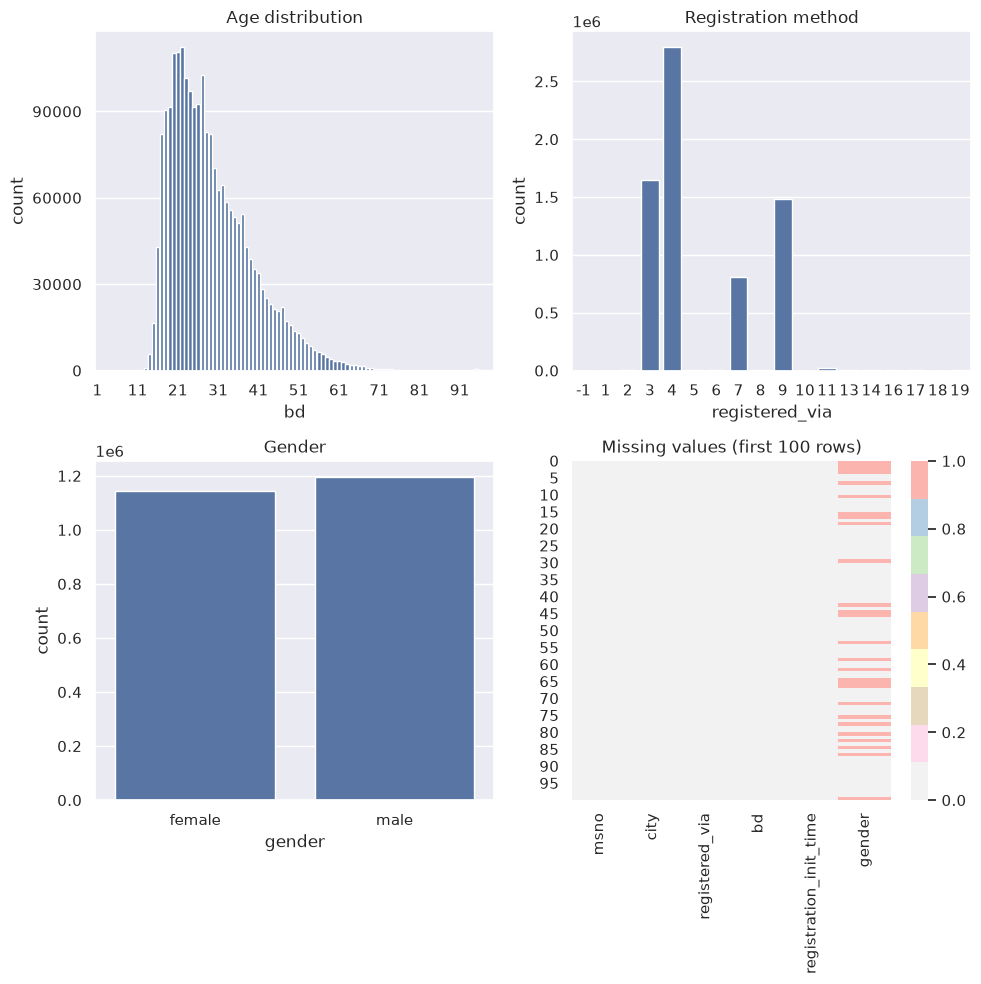

In [27]:
plt.figure(figsize=(10, 10))
plt.subplot(221)
sns.countplot(x=member_data["bd"][member_data["bd"] > 0][member_data["bd"] < 100])  # masking to avoid outliers
plt.title("Age distribution")
plt.xlabel("bd")
plt.ylabel("count")
plt.xticks(np.arange(0, 100, 10))
plt.yticks(np.arange(0, 120000, 30000))
plt.subplot(222)
sns.countplot(x=member_data["registered_via"])
plt.title("Registration method")
plt.xlabel("registered_via")
plt.ylabel("count")
plt.subplot(223)
sns.countplot(x=member_data["gender"])
plt.title("Gender")
plt.xlabel("gender")
plt.ylabel("count")
plt.subplot(224)
sns.heatmap(member_data[:100].isnull(), cmap="Pastel1_r")
plt.title("Missing values (first 100 rows)")
plt.tight_layout()
plt.show()

There is a peak in the age plot. There are some favourite/most-used registration methods. The gender plot is approximately balanced. Only gender data is missing (null).

Gender can be neglected because most values are unknown and the known ones are almost equally distributed. Methods 3, 4, 7 and 9 are preferred. As feature engineering we can build a flag for whether `registered_via` comes from a most-used method, and bin the age into ranges.

In [28]:
member_data["registered_via"].nunique()

18

In [29]:
member_data["msno"].nunique()

6769473

In [30]:
member_data["registered_via"].value_counts()

registered_via
 4     2793213
 3     1643208
 9     1482863
 7      805895
 11      25047
 13       5455
 8        3982
 5        3115
 17       1494
 2        1452
 6        1213
 19        974
 16        888
 14        615
 1          43
 10         10
 18          5
-1           1
Name: count, dtype: int64

In [31]:
tabla_percentiles(member_data["registered_via"])

,valor
0.000,-1.0
10.000,3.0
20.000,3.0
30.000,4.0
40.000,4.0
50.000,4.0
60.000,4.0
70.000,7.0
80.000,9.0
90.000,9.0


**Members.**

- `city`: there are 21 cities and city 1 dominates. Cities 4, 5, 13, 15 and 22 follow.
- `bd` (age): contains negative values and values greater than 100. The median is 0 because missing age was stored as 0. Valid values concentrate on young ages.
- `gender`: almost all values are null, and among known values the split is ~50/50, so it adds little.
- `registered_via`: there are 18 methods. The most used are 3, 4, 7 and 9, and invalid negative values appear.
- Proposed features: a flag for popular registration method and age grouped into ranges.

---
**Previous:** `01_target_overview.ipynb` · **Next:** `03_transactions.ipynb`